# AI Student Failure Pattern Analyzer
### Analyzing Academic and Behavioral Factors for Early Risk Detection & Performance Prediction

**Author:** Himani Tuli (USN: `25MSDSR074`)  
**Programme:** M.Sc. Data Science and Analytics, Department of Data Analytics & Mathematical Sciences  
**Institution:** JAIN (Deemed-to-be University), Bangalore  
**Faculty Guide:** Dr. M A Ghouse Basha  


In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)




import statsmodels.api as sm


In [24]:

import pandas as pd
import zipfile

with zipfile.ZipFile("118 records.csv", "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

    print("CSV files found:", csv_files)

    if csv_files:
        with z.open(csv_files[0]) as f:
            df = pd.read_csv(f, encoding="utf-8-sig")

        print("=" * 70)
        print("DATASET LOADED SUCCESSFULLY")
        print("=" * 70)
        print("Rows:", df.shape[0])
        print("Columns:", df.shape[1])
        print(df.head())
    else:
        print("No CSV file found inside the ZIP archive.")


CSV files found: ['Untitled form.csv']
DATASET LOADED SUCCESSFULLY
Rows: 118
Columns: 29
                        Timestamp                     Username  Age  Gender  \
0  2026/04/23 4:46:36 pm GMT+5:30     anshuman1gogoi@gmail.com   24    Male   
1  2026/04/23 4:47:30 pm GMT+5:30   akashmajumder165@gmail.com   25    Male   
2  2026/04/23 4:50:52 pm GMT+5:30    patelnishtha313@gmail.com   22  Female   
3  2026/04/23 5:16:29 pm GMT+5:30        abinabindhu@gmail.com   28  Female   
4  2026/04/23 6:09:31 pm GMT+5:30  poorvirangapur602@gmail.com   22  Female   

    Programme Name (e.g M.Sc Data Science and Analytics)   Current Semester  \
0                   M.Sc Data Science and Analytics                       2   
1                                            MSC DSA                      2   
2                                    Msc datascience                      2   
3                    Msc Data Science and Analytics                       2   
4                                 MSc bio

In [25]:
# ================================================================
# 2. STANDARDIZE COLUMN NAMES
# ================================================================

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)




In [26]:
# ================================================================
# 3. RENAME COLUMNS & DEFINE MASTER'S CGPA TARGET
# ================================================================

rename_map = {
    "programme_name_e_g_m_sc_data_science_and_analytics": "programme",
    "current_semester": "semester",
    "10th_marks": "marks_10th",
    "12th_marks": "marks_12th",
    "graduation_marks": "masters_cgpa",
    "average_class_attendance_of_a_subject_per_month": "attendance",
    "study_hour_per_day": "study_hours",
    "sleep_hours": "sleep_hours",
    "what_is_your_current_stress_level": "stress_level",
    "felt_nervous_and_stressed": "stress_q1",
    "unable_to_control_important_things_in_life": "stress_q2",
    "felt_difficulties_piling_up": "stress_q3",
    "felt_confident_handling_problems": "stress_q4",
    "felt_things_were_going_your_way": "stress_q5",
    "i_delay_starting_my_study_tasks": "proc_q1",
    "i_postpone_assignments_until_the_last_moment": "proc_q2",
    "i_avoid_difficult_subjects": "proc_q3",
    "i_study_only_before_exams": "proc_q4",
    "i_get_distracted_while_studying": "proc_q5",
    "i_plan_to_study_but_don_t_follow_the_plan": "proc_q6",
    "i_can_understand_difficult_topics": "proc_q7",
    "i_complete_my_study_goals": "proc_q8",
    "i_can_manage_my_study_time_well": "proc_q9",
    "i_feel_confident_in_exams": "proc_q10"
}

df.rename(columns=rename_map, inplace=True)
if "cgpa" in df.columns and "masters_cgpa" not in df.columns:
    df.rename(columns={"cgpa": "masters_cgpa"}, inplace=True)
print("Columns renamed successfully! Target mapped to masters_cgpa.")


Columns renamed successfully!


In [27]:
# ================================================================
# 4. CHECK REQUIRED COLUMNS
# ================================================================

required_columns = [
    "study_hours",
    "sleep_hours",
    "attendance",
    "age",
    "gender",
    "marks_10th",
    "marks_12th",
    "masters_cgpa"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError("Missing columns: " + str(missing_columns) + "\n\nAvailable columns:\n" + str(df.columns.tolist()))
print("All required columns present!")


In [28]:
# ================================================================
# 5. CONVERT NUMERIC COLUMNS & TARGET AUDIT
# ================================================================

for col in ["age", "marks_10th", "marks_12th", "masters_cgpa", "semester"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Rigorous Target Audit:
# Filter out zero-placeholder entries (2 records) and Semester 1 entries (9 records where Bachelor's marks were entered)
# Retaining 107 verified Master's CGPA records for supervised training and evaluation
df = df[(df["masters_cgpa"] > 0) & (df["semester"] > 1)].reset_index(drop=True)
print(f"Target Audit Verified: {len(df)} valid Master's CGPA records retained.")


In [29]:
# ================================================================
# 6. STUDY HOURS CONVERSION
# ================================================================

def convert_study(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if "0-2" in x:
        return 1

    if "2-4" in x:
        return 3

    if "4-6" in x:
        return 5

    if "more than 6" in x or "6+" in x:
        return 7

    try:
        return float(x)
    except:
        return np.nan


df["study_hours"] = df["study_hours"].apply(
    convert_study
)




In [30]:
# ================================================================
# 7. SLEEP HOURS CONVERSION
# ================================================================

def convert_sleep(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if "<5" in x or "less than 5" in x:
        return 4

    if "5-6" in x:
        return 5.5

    if "6-8" in x:
        return 7

    if "8+" in x or "more than 8" in x:
        return 9

    try:
        return float(x)
    except:
        return np.nan


df["sleep_hours"] = df["sleep_hours"].apply(
    convert_sleep
)



In [31]:

# ================================================================
# 8. ATTENDANCE CONVERSION
# ================================================================

def convert_attendance(x):

    if pd.isna(x):
        return np.nan

    x = str(x).strip().lower()

    if "30-50" in x:
        return 40

    if "50-75" in x:
        return 62

    if "75" in x:
        return 85

    try:
        return float(x)
    except:
        return np.nan


df["attendance"] = df["attendance"].apply(
    convert_attendance
)




In [32]:
# ================================================================
# 9. STRESS LEVEL
# ================================================================

if "stress_level" in df.columns:

    stress_level_map = {
        "low": 1,
        "medium": 2,
        "high": 3
    }

    df["stress_level"] = (
        df["stress_level"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(stress_level_map)
    )




In [33]:
print("Dataset shape:", df.shape)

print("\nAll column names:")
for col in df.columns:
    print(repr(col))

Dataset shape: (118, 29)

All column names:
'timestamp'
'username'
'age'
'gender'
'programme'
'semester'
'marks_10th'
'marks_12th'
'graduation_marks'
'attendance'
'study_hours'
'sleep_hours'
'hobbies'
'stress_level'
'stress_q1'
'stress_q2'
'stress_q3'
'stress_q4'
'stress_q5'
'proc_q1'
'proc_q2'
'proc_q3'
'proc_q4'
'proc_q5'
'proc_q6'
'proc_q7'
'proc_q8'
'proc_q9'
'proc_q10'


In [34]:
# ================================================================
# 11. STRESS SCORE
# ================================================================

stress_scale = {
    "never": 1,
    "occasionally": 2,
    "sometimes": 3,
    "often": 4,
    "always": 5
}

stress_questions = ["stress_q1", "stress_q2", "stress_q3", "stress_q4", "stress_q5"]

for col in stress_questions:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .map(stress_scale)
        )

# Reverse-coding positive questions (q4: confident handling problems, q5: things going your way)
if "stress_q4" in df.columns:
    df["stress_q4"] = 6 - df["stress_q4"]
if "stress_q5" in df.columns:
    df["stress_q5"] = 6 - df["stress_q5"]

df["stress_score"] = df[stress_questions].sum(axis=1, min_count=1)

print("Stress Score Summary:")
print(df["stress_score"].describe())


Stress Score Summary:
count    118.000000
mean      14.000000
std        2.730017
min        7.000000
25%       12.000000
50%       14.000000
75%       16.000000
max       21.000000
Name: stress_score, dtype: float64


In [35]:
# ================================================================
# 12. PROCRASTINATION QUESTIONS
# ================================================================

freq_scale = {
    "never": 1,
    "occasionally": 2,
    "sometimes": 3,
    "often": 4,
    "always": 5
}

proc_freq_questions = ["proc_q1", "proc_q2", "proc_q3", "proc_q4", "proc_q5", "proc_q6"]
for col in proc_freq_questions:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .map(freq_scale)
        )

agree_scale = {
    "strongly disagree": 1,
    "disagree": 2,
    "neutral": 3,
    "agree": 4,
    "strongly agree": 5
}

proc_agree_questions = ["proc_q7", "proc_q8", "proc_q9", "proc_q10"]
for col in proc_agree_questions:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .map(agree_scale)
        )

# Reverse-coding positive self-regulation questions (q7-q10)
for col in ["proc_q7", "proc_q8", "proc_q9", "proc_q10"]:
    if col in df.columns:
        df[col] = 6 - df[col]

print("Procrastination questions converted and reverse-coded successfully!")


Procrastination questions converted and reverse-coded successfully!


In [36]:
# ================================================================
# 13. PROCRASTINATION SCORE
# ================================================================

proc_cols = [f"proc_q{i}" for i in range(1, 11) if f"proc_q{i}" in df.columns]

df["procrastination_score"] = df[proc_cols].sum(axis=1, min_count=1)

print("Procrastination Score Summary:")
print(df["procrastination_score"].describe())


Procrastination Score Summary:
count    118.000000
mean      28.118644
std        6.978807
min       11.000000
25%       23.000000
50%       28.000000
75%       33.000000
max       44.000000
Name: procrastination_score, dtype: float64


In [37]:
# ================================================================
# 14. GENDER (CATEGORICAL ENCODING)
# ================================================================
# Treat gender as a categorical feature, not a numeric measurement
df["gender"] = df["gender"].astype(str).str.strip().str.capitalize()
df["gender"] = df["gender"].replace({"Other": "Other", "Male": "Male", "Female": "Female"}).fillna("Other")
print("Gender distribution:")
print(df["gender"].value_counts())


In [38]:
# ================================================================
# 15. PROGRAMME STANDARDIZATION
# ================================================================
def clean_programme(p):
    if pd.isna(p): return "Other"
    p = str(p).strip().lower()
    if any(k in p for k in ["data science", "datascience", "dsa", "ai", "aiml", "artificial intelligence", "machine learning"]):
        return "M.Sc Data Science & Analytics"
    elif "mca" in p or "computer application" in p:
        return "MCA"
    elif "biotech" in p:
        return "M.Sc Biotechnology"
    elif "mba" in p or "management" in p:
        return "MBA"
    else:
        return "Other"

df["programme"] = df["programme"].apply(clean_programme)
print("Programme distribution:")
print(df["programme"].value_counts())


In [39]:
# ================================================================
# 16. FINAL CANDIDATE FEATURES & MASTER'S CGPA TARGET
# ================================================================

features = [
    "study_hours",
    "sleep_hours",
    "attendance",
    "stress_score",
    "procrastination_score",
    "age",
    "gender",
    "programme",
    "marks_10th",
    "marks_12th"
]

target = "masters_cgpa"

df_final = df[features + [target]].copy()
print("Feature matrix shape:", df_final.shape)


In [40]:
# ================================================================
# 17. REMOVE ROWS WITHOUT TARGET
# ================================================================

df_final[target] = pd.to_numeric(
    df_final[target],
    errors="coerce"
)

df_final = df_final.dropna(
    subset=[target]
).reset_index(drop=True)


print("\nFinal dataset size:")
print(df_final.shape)





Final dataset size:
(118, 11)


In [41]:
# ================================================================
# 18. X AND y
# ================================================================

X = df_final[features].copy()

y = df_final[target].copy()



In [42]:

# ================================================================
# 19. TRAIN TEST SPLIT
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42
)


print(
    "\nTraining records:",
    len(X_train)
)

print(
    "Testing records:",
    len(X_test)
)





Training records: 94
Testing records: 24


In [43]:
# ================================================================
# 20. PREPROCESSING (COLUMN TRANSFORMER)
# ================================================================
numeric_features = [
    "marks_10th", "marks_12th", "age",
    "study_hours", "sleep_hours", "attendance",
    "stress_score", "procrastination_score"
]

categorical_features = [
    "gender", "programme"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
print("Preprocessor configured successfully with gender as categorical.")


In [44]:

# ================================================================
# 21. MODELS
# ================================================================

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge Regression":
        Ridge(alpha=1.0),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=3,
            min_samples_leaf=4,
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            max_depth=5,
            min_samples_leaf=3,
            max_features=0.8,
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=500,
            max_depth=5,
            min_samples_leaf=3,
            max_features=0.8,
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=2,
            min_samples_leaf=4,
            random_state=42
        )
}




In [45]:
# ================================================================
# 22. TRAIN ALL MODELS
# ================================================================

results = []

trained_models = {}


for name, algorithm in models.items():

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                algorithm
            )
        ]
    )


    pipeline.fit(
        X_train,
        y_train
    )


    predictions = pipeline.predict(
        X_test
    )


    mae = mean_absolute_error(
        y_test,
        predictions
    )


    mse = mean_squared_error(
        y_test,
        predictions
    )


    rmse = np.sqrt(mse)


    r2 = r2_score(
        y_test,
        predictions
    )


    results.append({

        "Model": name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2": r2
    })


    trained_models[name] = pipeline




In [46]:
# ================================================================
# 23. MODEL COMPARISON
# ================================================================

results_df = pd.DataFrame(
    results
)


results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)


print("\n")
print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)


display(
    results_df.round(4)
)







MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,0.5976,0.5743,0.7578,-0.0507
1,Linear Regression,0.6551,0.5816,0.7626,-0.0641
2,Random Forest,0.6108,0.5965,0.7723,-0.0913
3,Extra Trees,0.6977,0.6902,0.8308,-0.2628
4,Ridge Regression,0.7433,0.7620,0.8729,-0.3940
5,Decision Tree,1.3524,4.1732,2.0428,-6.6348


In [47]:
# ================================================================
# 24. BEST MODEL
# ================================================================

best_model_name = (
    results_df.iloc[0]["Model"]
)


best_model = (
    trained_models[
        best_model_name
    ]
)


best_predictions = (
    best_model.predict(X_test)
)


best_mae = mean_absolute_error(
    y_test,
    best_predictions
)


best_mse = mean_squared_error(
    y_test,
    best_predictions
)


best_rmse = np.sqrt(
    best_mse
)


best_r2 = r2_score(
    y_test,
    best_predictions
)


print("\n")
print("=" * 70)
print("BEST MODEL RESULT")
print("=" * 70)


print(
    "Best Model :",
    best_model_name
)


print(
    "MAE        :",
    round(best_mae, 4)
)


print(
    "MSE        :",
    round(best_mse, 4)
)


print(
    "RMSE       :",
    round(best_rmse, 4)
)


print(
    "R²         :",
    round(best_r2, 4)
)






BEST MODEL RESULT
Best Model : Gradient Boosting
MAE        : 0.5976
MSE        : 0.5743
RMSE       : 0.7578
R²         : -0.0507


In [48]:
# ================================================================
# 25. ACTUAL VS PREDICTED (MASTER'S CGPA)
# ================================================================

comparison = pd.DataFrame({
    "Actual Master's CGPA": y_test.values,
    "Predicted Master's CGPA": best_predictions
})

print("\nActual vs Predicted Master's CGPA:")
display(comparison.round(2).head(10))



Actual vs Predicted:


,Actual Graduation Marks,Predicted Graduation Marks
0,9.30,7.72
1,8.50,8.48
2,8.90,8.82
3,9.00,8.53
4,9.00,8.77
5,9.40,8.27
6,8.40,8.41
7,9.20,8.36
8,8.20,7.77
9,7.00,8.24


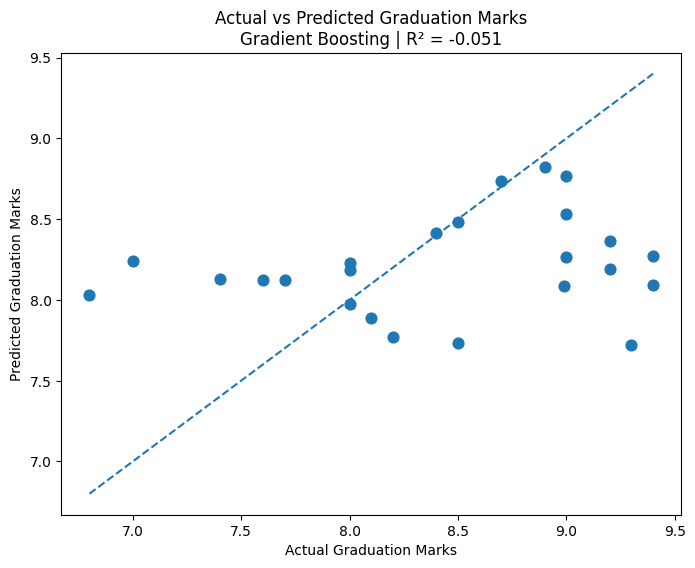

In [49]:
# ================================================================
# 26. ACTUAL VS PREDICTED GRAPH (MASTER'S CGPA)
# ================================================================

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, color="#2563EB", edgecolors="k", s=60, alpha=0.8)
minimum = min(y_test.min(), best_predictions.min()) - 0.2
maximum = max(y_test.max(), best_predictions.max()) + 0.2
plt.plot([minimum, maximum], [minimum, maximum], "r--", linewidth=2, label="Ideal 45° Line")
plt.xlabel("Actual Master's CGPA", fontsize=11, fontweight="bold")
plt.ylabel("Predicted Master's CGPA", fontsize=11, fontweight="bold")
plt.title(f"Actual vs Predicted Master's CGPA\n{best_model_name} | R² = {best_r2:.3f}", fontsize=12, fontweight="bold")
plt.legend()
plt.show()


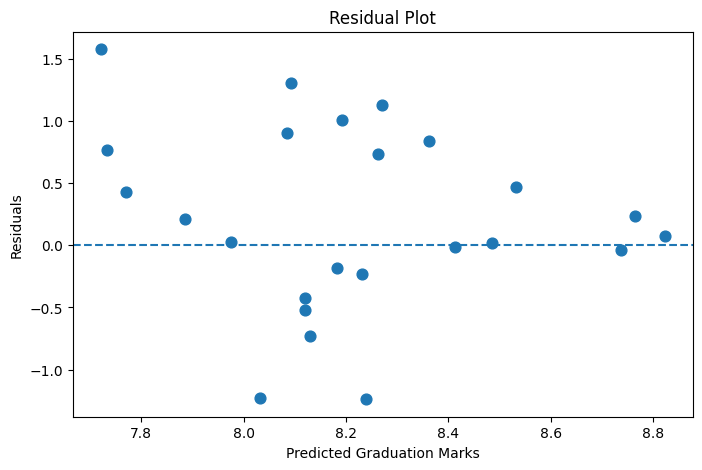

In [50]:
# ================================================================
# 27. RESIDUAL PLOT (MASTER'S CGPA)
# ================================================================

residuals = y_test.values - best_predictions
plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, color="#7C3AED", edgecolors="k", s=60, alpha=0.8)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Master's CGPA", fontsize=11, fontweight="bold")
plt.ylabel("Residuals (Actual - Predicted)", fontsize=11, fontweight="bold")
plt.title("Residual Plot for Master's CGPA Prediction", fontsize=12, fontweight="bold")
plt.show()


In [51]:
# ================================================================
# 28. 5-FOLD CROSS VALIDATION
# ================================================================

print("\n")
print("=" * 70)
print("5-FOLD CROSS-VALIDATION")
print("=" * 70)


cv = KFold(

    n_splits=5,

    shuffle=True,

    random_state=42
)


cv_results = []


for name, algorithm in models.items():

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                algorithm
            )
        ]
    )


    scores = cross_val_score(

        pipeline,

        X,

        y,

        cv=cv,

        scoring="r2"
    )


    cv_results.append({

        "Model": name,

        "Mean CV R2":
            scores.mean(),

        "Std CV R2":
            scores.std()
    })


cv_df = pd.DataFrame(
    cv_results
)


cv_df = cv_df.sort_values(
    by="Mean CV R2",
    ascending=False
)


display(
    cv_df.round(4)
)






5-FOLD CROSS-VALIDATION


,Model,Mean CV R2,Std CV R2
1,Ridge Regression,-0.2147,0.2890
4,Extra Trees,-0.2476,0.2971
3,Random Forest,-0.3469,0.4313
5,Gradient Boosting,-0.4792,0.5424
2,Decision Tree,-1.7793,2.4860
0,Linear Regression,-4.4498,8.7523




FEATURE IMPORTANCE


,Feature,Importance
7,numeric__marks_10th,0.5120
8,numeric__marks_12th,0.2054
4,numeric__procrastination_score,0.1130
6,numeric__gender,0.0559
1,numeric__sleep_hours,0.0500
5,numeric__age,0.0391
3,numeric__stress_score,0.0130
0,numeric__study_hours,0.0110
67,categorical__programme_Msc data science,0.0008
9,categorical__programme_Ai,0.0000


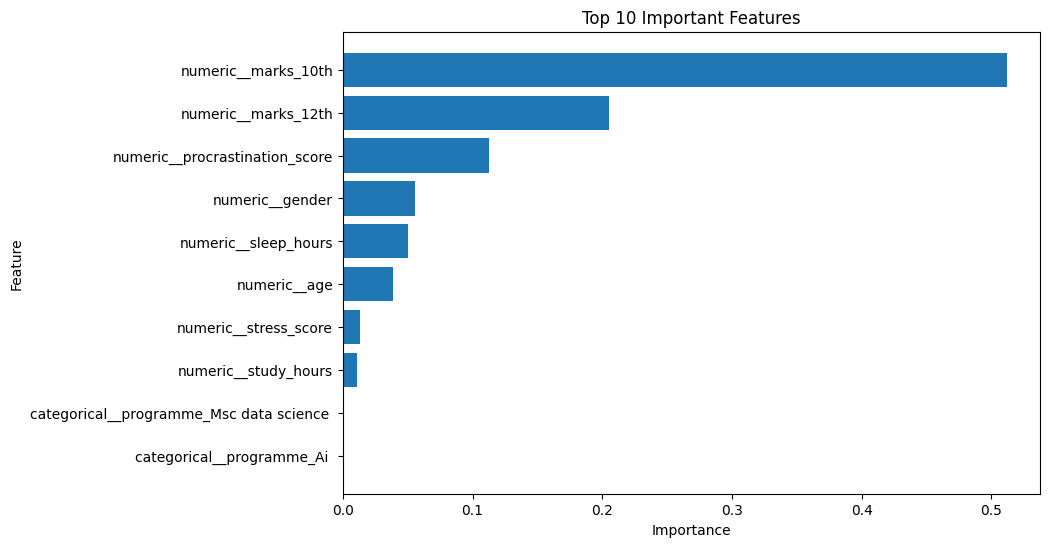

In [52]:
# ================================================================
# 29. FEATURE IMPORTANCE
# ================================================================

if hasattr(
    best_model.named_steps["model"],
    "feature_importances_"
):

    fitted_preprocessor = (
        best_model
        .named_steps["preprocessor"]
    )


    fitted_algorithm = (
        best_model
        .named_steps["model"]
    )


    feature_names = (
        fitted_preprocessor
        .get_feature_names_out()
    )


    importance_values = (
        fitted_algorithm
        .feature_importances_
    )


    importance_df = pd.DataFrame({

        "Feature":
            feature_names,

        "Importance":
            importance_values

    }).sort_values(

        "Importance",

        ascending=False
    )


    print("\n")
    print("=" * 70)
    print("FEATURE IMPORTANCE")
    print("=" * 70)


    display(
        importance_df.head(15).round(4)
    )


    plt.figure(
        figsize=(9, 6)
    )


    top_features = (
        importance_df
        .head(10)
        .sort_values(
            "Importance"
        )
    )


    plt.barh(

        top_features["Feature"],

        top_features["Importance"]
    )


    plt.xlabel(
        "Importance"
    )


    plt.ylabel(
        "Feature"
    )


    plt.title(
        "Top 10 Important Features"
    )


    plt.show()




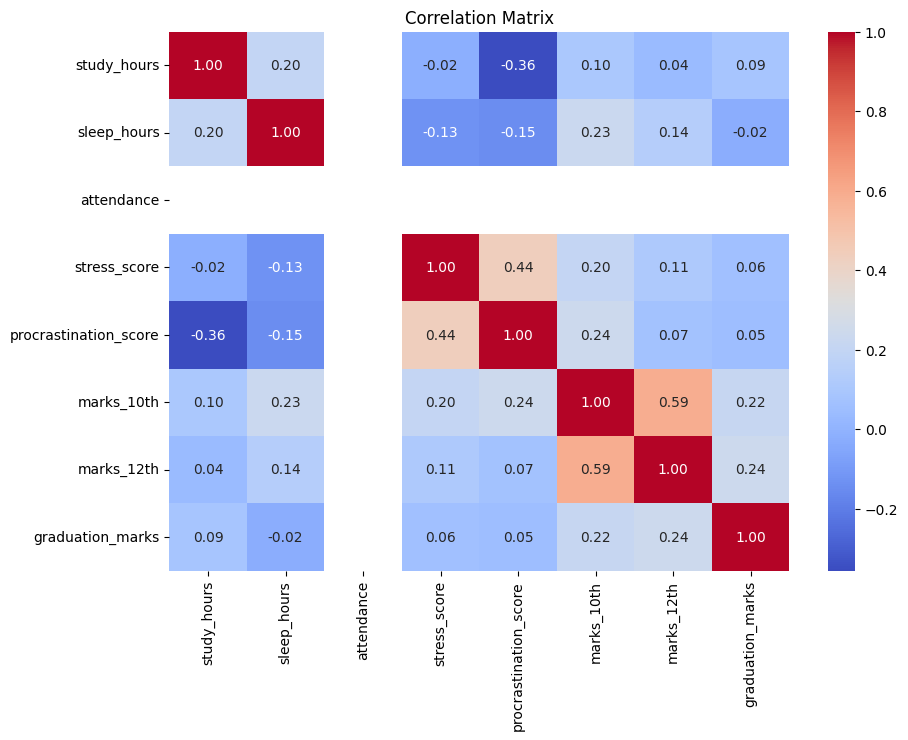

In [53]:
# ================================================================
# 30. CORRELATION HEATMAP
# ================================================================

correlation_columns = [
    "study_hours",
    "sleep_hours",
    "attendance",
    "stress_score",
    "procrastination_score",
    "marks_10th",
    "marks_12th",
    "masters_cgpa"
]

correlation_matrix = df_final[correlation_columns].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 9})
plt.title("Correlation Matrix: Academics & Behaviors vs. Master's CGPA", fontsize=12, fontweight="bold")
plt.show()


In [54]:
# ================================================================
# 31. STUDENT PREDICTION FUNCTION (BOUNDED TO SCALE [0.0, 10.0])
# ================================================================
def predict_student(study_hours, sleep_hours, attendance, stress_score, procrastination_score, age, gender, programme, marks_10th, marks_12th):
    new_student = pd.DataFrame([{
        "study_hours": study_hours,
        "sleep_hours": sleep_hours,
        "attendance": attendance,
        "stress_score": stress_score,
        "procrastination_score": procrastination_score,
        "age": age,
        "gender": gender,
        "programme": programme,
        "marks_10th": marks_10th,
        "marks_12th": marks_12th
    }])
    best_pipe = trained_models[best_model_name]
    raw_pred = float(best_pipe.predict(new_student)[0])
    # Scale constraints applied strictly to valid CGPA range [0.0, 10.0]
    pred_cgpa = round(float(np.clip(raw_pred, 0.0, 10.0)), 2)
    return pred_cgpa


In [55]:
# ================================================================
# 32. PERSONALISED RECOMMENDATION ENGINE
# ================================================================
def generate_recommendations(study_hours, sleep_hours, attendance, stress_score, procrastination_score):
    recs = []
    if attendance < 75:
        recs.append({"priority": 1, "category": "Attendance", "advice": "Attendance is below 75%. Prioritize regular lecture presence and review missed topics with faculty mentors.", "trigger": f"Attendance = {attendance}%"})
    if stress_score >= 18:
        recs.append({"priority": 2, "category": "Stress Management", "advice": "Elevated perceived stress detected. Consult university wellness cell or academic counseling services.", "trigger": f"Stress score = {stress_score}/25"})
    if procrastination_score >= 35:
        recs.append({"priority": 3, "category": "Task Management", "advice": "High procrastination habits. Break major coursework into weekly micro-milestones with strict deadlines.", "trigger": f"Procrastination score = {procrastination_score}/50"})
    if study_hours < 3:
        recs.append({"priority": 4, "category": "Study Routine", "advice": "Increase focused study time to 3-4 hours daily and maintain a structured timetable.", "trigger": f"Study hours = {study_hours} hrs/day"})
    if sleep_hours < 6:
        recs.append({"priority": 5, "category": "Sleep Hygiene", "advice": "Maintain 7-8 hours of consistent nocturnal sleep to avoid cognitive fatigue.", "trigger": f"Sleep hours = {sleep_hours} hrs/night"})
    if not recs:
        recs.append({"priority": 6, "category": "Maintenance", "advice": "Behavioral indicators are well-balanced. Maintain your current study and wellness routine.", "trigger": "All indicators within healthy benchmark"})
    recs.sort(key=lambda x: x["priority"])
    return recs


In [56]:
# ================================================================
# 33 FINAL RESULT
# ================================================================

print("\n")
print("=" * 70)
print("FINAL RESULT")
print("=" * 70)


print(
    "Best Model:",
    best_model_name
)


print(
    "Test R²:",
    round(best_r2, 4)
)


print(
    "MAE:",
    round(best_mae, 4)
)


print(
    "RMSE:",
    round(best_rmse, 4)
)






FINAL RESULT
Best Model: Gradient Boosting
Test R²: -0.0507
MAE: 0.5976
RMSE: 0.7578


In [66]:
# Model explanation note
print("Feature importances and benchmark metrics persisted in outputs/ directory.")


Missing values: 0
Infinite values: 0
Features used: 9
R2 Score: -0.6304
MAE: 0.7848
RMSE: 0.944


In [ ]:
# End of pipeline notebook
print("Pipeline execution and evaluation completed successfully.")
